<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">UFC Opening &amp; Closing Odds — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 4,249 UFC fights from 14 January 2018 to 20 June 2026, the opening line and the closing prices of seven
sportsbooks on the moneyline and the total rounds, four prop markets from May 2020, the public betting split, the official
results and the fight stats of both fighters.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data. Only the counts of prices left out while the file
was built (125 markets, listed rule by rule in the README) cannot be recomputed: those prices are, by
definition, not in the file.

🥊 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/iiyon?utm_source=github&utm_medium=notebook&utm_campaign=ufc_oc&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/ufc-opening-closing-odds-7-books-props-fight-stats-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=ufc_oc&utm_content=whop_top) · free 20-fight sample, same layout, same 228 columns: [Kaggle](https://www.kaggle.com/datasets/oliviersportsdata/ufc-multimarket-sample-2025) · [Hugging Face](https://huggingface.co/datasets/oliviersportsdata/UFC-Multi-Market-Opening-Closing-Odds) · [GitHub](https://github.com/ovignez-hash/ufc-multi-market-opening-closing-odds).

## 0 · Setup

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

def find_csv():
    """The CSV of the full product: the largest UFC_Opening_Closing_Odds file wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("UFC_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", "UFC_Opening_Closing_Odds_2018-2026*.csv"), recursive=True)
                     if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError("UFC_Opening_Closing_Odds_2018-2026.csv not found: attach the dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
BYTES = open(PATH, "rb").read()
S = pd.read_csv(PATH, sep=";", encoding="utf-8-sig", dtype=str, keep_default_na=False)   # every cell as written
F = pd.read_csv(PATH, sep=";", encoding="utf-8-sig")                                      # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(BYTES) / 1e6:.2f} MB  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

SOURCES = ["Opener", "Betcris", "Heritage", "BetOnline", "Bovada", "BetAnything", "WilliamHill", "Everygame"]
BOOKS = SOURCES[1:]                                # the seven sportsbooks, closing prices; Opener = the opening line
NAME = {"WilliamHill": "William Hill", "Opener": "Opening line"}
MARKETS = {"ML": ["ML_A_US", "ML_A_Dec", "ML_B_US", "ML_B_Dec"],
           "Total": ["Total_Line", "Total_Over_US", "Total_Over_Dec", "Total_Under_US", "Total_Under_Dec"]}
PAIRS = {"ML": ("ML_A_US", "ML_B_US"), "Total": ("Total_Over_US", "Total_Under_US")}
KEY = {"ML": "ML_A_US", "Total": "Total_Line"}
PROPS = ["TR", "Dist", "End", "MOV"]
US_COLS = [c for c in F.columns if c.endswith("_US")]
CORE_US = [c for c in US_COLS if c.split("_")[0] in SOURCES]
PROP_US = [c for c in US_COLS if c.split("_")[0] in PROPS]

def imp(us):
    """Implied probability of an American price."""
    us = np.asarray(us, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(us < 0, -us / (100 - us), 100 / (us + 100))

def no_vig_a(a, b):
    """Implied probability of fighter A, margin removed proportionally."""
    pa, pb = imp(a), imp(b)
    return pa / (pa + pb)

RESULTS = []
def check(claim, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((claim, ok, detail))
    print(f"{'PASS' if ok else 'FAIL'}  {claim}" + (f"   [{detail}]" if detail else ""))

# Olivier Sports Data dark signature
BG, FG, FG2, GRID, CYAN, AMBER = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff", "#e3a008"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": GRID, "xtick.color": FG2, "ytick.color": FG2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlecolor": FG,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10, "legend.frameon": False})

UFC_Opening_Closing_Odds_2018-2026.csv  ·  4.41 MB  ·  4,249 rows  ·  228 columns


## 1 · The claims

Copied from the listing, the README shipped in the ZIP and the images of the listing. Nothing below is adjusted to
fit: if the file disagrees, the cell prints FAIL.

In [2]:
CLAIMS = {
 "fights": 4249,
 "columns": 228,
 "events": 354,
 "fighters": 1450,
 "first_date": "2018-01-14",
 "last_date": "2026-06-20",
 "fights_per_year": {
  "2018": 460,
  "2019": 510,
  "2020": 456,
  "2021": 508,
  "2022": 511,
  "2023": 519,
  "2024": 517,
  "2025": 520,
  "2026": 248
 },
 "prices_core": 117358,
 "prices_props": 136152,
 "prices_total": 253510,
 "results": {
  "Win": 4173,
  "Draw": 33,
  "No Contest": 43
 },
 "methods": {
  "U-DEC": 1660,
  "KO/TKO": 1338,
  "SUB": 735,
  "S-DEC": 411,
  "M-DEC": 51,
  "Overturned": 24,
  "CNC": 20,
  "DQ": 10
 },
 "women": 720,
 "titles": {
  "Championship": 158,
  "BMF": 5
 },
 "technical_decisions": 6,
 "decision_scores": {
  "decisions": 2122,
  "with_scores": 2093,
  "loser_first": 15
 },
 "coverage_fights": {
  "Opener": {
   "ML": 4209,
   "Total": 4200
  },
  "Betcris": {
   "ML": 3662,
   "Total": 3521
  },
  "Heritage": {
   "ML": 4184,
   "Total": 4211
  },
  "BetOnline": {
   "ML": 4218,
   "Total": 4203
  },
  "Bovada": {
   "ML": 4202,
   "Total": 2299
  },
  "BetAnything": {
   "ML": 2472,
   "Total": 2470
  },
  "WilliamHill": {
   "ML": 4224,
   "Total": 2216
  },
  "Everygame": {
   "ML": 4201,
   "Total": 4187
  }
 },
 "ml_coverage_by_year_pct": {
  "Opener": {
   "2018": 98,
   "2019": 99,
   "2020": 97,
   "2021": 98,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Betcris": {
   "2018": 100,
   "2019": 100,
   "2020": 99,
   "2021": 55,
   "2022": 31,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Heritage": {
   "2018": 99,
   "2019": 99,
   "2020": 95,
   "2021": 97,
   "2022": 100,
   "2023": 100,
   "2024": 99,
   "2025": 99,
   "2026": 99
  },
  "BetOnline": {
   "2018": 100,
   "2019": 100,
   "2020": 97,
   "2021": 98,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Bovada": {
   "2018": 99,
   "2019": 98,
   "2020": 97,
   "2021": 96,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "BetAnything": {
   "2018": 0,
   "2019": 0,
   "2020": 0,
   "2021": 31,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "WilliamHill": {
   "2018": 99,
   "2019": 99,
   "2020": 99,
   "2021": 99,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 99
  },
  "Everygame": {
   "2018": 99,
   "2019": 99,
   "2020": 99,
   "2021": 97,
   "2022": 96,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  }
 },
 "total_coverage_by_year_pct": {
  "Opener": {
   "2018": 99,
   "2019": 97,
   "2020": 97,
   "2021": 97,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Betcris": {
   "2018": 100,
   "2019": 100,
   "2020": 100,
   "2021": 55,
   "2022": 31,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 42
  },
  "Heritage": {
   "2018": 98,
   "2019": 99,
   "2020": 99,
   "2021": 97,
   "2022": 100,
   "2023": 100,
   "2024": 99,
   "2025": 99,
   "2026": 100
  },
  "BetOnline": {
   "2018": 99,
   "2019": 97,
   "2020": 97,
   "2021": 97,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Bovada": {
   "2018": 0,
   "2019": 0,
   "2020": 0,
   "2021": 7,
   "2022": 100,
   "2023": 100,
   "2024": 99,
   "2025": 100,
   "2026": 80
  },
  "BetAnything": {
   "2018": 0,
   "2019": 0,
   "2020": 0,
   "2021": 31,
   "2022": 100,
   "2023": 99,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "WilliamHill": {
   "2018": 35,
   "2019": 0,
   "2020": 0,
   "2021": 5,
   "2022": 98,
   "2023": 99,
   "2024": 100,
   "2025": 60,
   "2026": 73
  },
  "Everygame": {
   "2018": 98,
   "2019": 99,
   "2020": 100,
   "2021": 98,
   "2022": 93,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  }
 },
 "betting_split_fights": {
  "ML": 4234,
  "Total": 4177
 },
 "fights_books_on_different_total_lines": 1380,
 "b_favourite_pct": 70.8,
 "favourite_won": [
  2755,
  4094
 ],
 "betcris_gap": {
  "from": "2021-07-24",
  "to": "2022-08-20"
 },
 "betcris_last_total": "2026-03-21",
 "betanything_first_month": "2021-09",
 "props_first_date": "2020-05-09",
 "props_fights": {
  "TR": 2999,
  "Dist": 2959,
  "End": 2640,
  "MOV": 2958
 },
 "prop_books": [
  "BetMGM",
  "BetRivers",
  "Caesars",
  "DraftKings",
  "FanDuel",
  "Fanatics",
  "Fliff",
  "Hard Rock",
  "Kalshi",
  "Novig",
  "PartyCasino",
  "ProphetX",
  "SugarHouse",
  "theScore Bet"
 ],
 "total_lines": [
  0.5,
  1.5,
  2.5,
  3.5,
  4.5
 ],
 "ledet_fights_without_ml": 4,
 "props_columns": 120,
 "women_catchweight": 7,
 "overturned": {
  "No Contest": 23,
  "Draw": 1
 },
 "tr_best_lines_differ": 528,
 "markets_removed": 125
}
COVERS = {
 "cover_1_winner_ml": {
  "2024-02-17|Ilia Topuria": [
   -105,
   114,
   115,
   115,
   112
  ],
  "2024-04-13|Alex Pereira": [
   -140,
   -140,
   -135,
   -135,
   -140
  ],
  "2025-06-28|Ilia Topuria": [
   -525,
   -453,
   -435,
   -420,
   -435
  ],
  "2025-10-04|Alex Pereira": [
   180,
   219,
   210,
   225,
   214
  ],
  "2025-11-15|Islam Makhachev": [
   -260,
   -315,
   -275,
   -300,
   -315
  ]
 },
 "cover_2_fight": {
  "date": "2024-02-17",
  "a": "Ilia Topuria",
  "b": "Alexander Volkanovski",
  "winner": "Ilia Topuria",
  "method": "KO/TKO",
  "round": "2",
  "rows": {
   "Opener": [
    -105,
    -115,
    3.5,
    -155,
    125
   ],
   "Betcris": [
    114,
    -143,
    3.5,
    -139,
    109
   ],
   "Heritage": [
    112,
    -136,
    4.5,
    105,
    -129
   ],
   "BetOnline": [
    115,
    -135,
    3.5,
    -144,
    114
   ],
   "Bovada": [
    115,
    -130,
    2.5,
    -210,
    160
   ],
   "BetAnything": [
    105,
    -135,
    3.5,
    -135,
    105
   ],
   "WilliamHill": [
    -110,
    -110,
    3.5,
    -125,
    -110
   ],
   "Everygame": [
    110,
    -140,
    3.5,
    -135,
    105
   ]
  },
  "props": {
   "dist_yes": 120,
   "dist_no": -164,
   "mov_a_ko": 350,
   "bet_ml_a": 62,
   "bet_over": 70
  }
 },
 "cover_3_moves": {
  "event": "UFC 300: Pereira vs. Hill",
  "rows": {
   "Jamahal Hill|Alex Pereira": [
    120,
    110,
    120,
    114,
    "Alex Pereira"
   ],
   "Yan Xiaonan|Zhang Weili": [
    295,
    351,
    325,
    360,
    "Zhang Weili"
   ],
   "Max Holloway|Justin Gaethje": [
    185,
    137,
    155,
    140,
    "Max Holloway"
   ],
   "Arman Tsarukyan|Charles Oliveira": [
    -240,
    -215,
    -220,
    -220,
    "Arman Tsarukyan"
   ],
   "Cody Brundage|Bo Nickal": [
    1100,
    777,
    850,
    867,
    "Bo Nickal"
   ]
  }
 },
 "cover_4_public_split": {
  "event": "UFC 317: Topuria vs. Oliveira",
  "rows": {
   "Charles Oliveira|Ilia Topuria": [
    71,
    29,
    74,
    "Ilia Topuria",
    "KO/TKO",
    "1"
   ],
   "Kai Kara-France|Alexandre Pantoja": [
    68,
    32,
    6,
    "Alexandre Pantoja",
    "SUB",
    "3"
   ],
   "Brandon Royval|Joshua Van": [
    43,
    57,
    78,
    "Joshua Van",
    "U-DEC",
    "3"
   ],
   "Renato Moicano|Beneil Dariush": [
    39,
    61,
    94,
    "Beneil Dariush",
    "U-DEC",
    "3"
   ],
   "Felipe Lima|Payton Talbott": [
    28,
    72,
    60,
    "Payton Talbott",
    "U-DEC",
    "3"
   ]
  }
 },
 "cover_5_coverage_pct": {
  "Opener": [
   99.1,
   98.8
  ],
  "Betcris": [
   86.2,
   82.9
  ],
  "Heritage": [
   98.5,
   99.1
  ],
  "BetOnline": [
   99.3,
   98.9
  ],
  "Bovada": [
   98.9,
   54.1
  ],
  "BetAnything": [
   58.2,
   58.1
  ],
  "WilliamHill": [
   99.4,
   52.2
  ],
  "Everygame": [
   98.9,
   98.5
  ]
 },
 "cover_5_props": {
  "TR": 2999,
  "Dist": 2959,
  "End": 2640,
  "MOV": 2958
 },
 "cover_6_tiles": {
  "fights": 4249,
  "events": 354,
  "fighters": 1450,
  "sources": 8,
  "prices": 253510,
  "columns": 228,
  "bet_ml_fights": 4234
 }
}

## 2 · The file

One CSV, one row per fight, semicolon-separated, UTF-8 with a BOM; in Excel, open it with Data > From Text/CSV. 36 fight
columns, then 9 columns per source (the moneylines of the 8 sources, then their totals), then the prop columns.

In [3]:
FIGHT = ["Fight_ID", "Date", "Event", "Location", "Attendance", "PPV_Sales", "Card_Segment", "Bout_Order", "Title",
         "Weight_Class", "Gender", "Fighter_A", "Fighter_A_ID", "Fighter_A_Country", "Fighter_B", "Fighter_B_ID",
         "Fighter_B_Country", "Fighter_A_Result", "Fighter_B_Result", "Winner", "Method", "Method_Detail", "Round",
         "Finish_Time", "Fighter_A_Knockdowns", "Fighter_B_Knockdowns", "Fighter_A_Sig_Strikes", "Fighter_B_Sig_Strikes",
         "Fighter_A_Takedowns", "Fighter_B_Takedowns", "Fighter_A_Sub_Attempts", "Fighter_B_Sub_Attempts",
         "ML_A_Bet%", "ML_B_Bet%", "Total_Over_Bet%", "Total_Under_Bet%"]
core = [f"{s}_{f}" for m in MARKETS for s in SOURCES for f in MARKETS[m]]
props = [c for c in F.columns if c.split("_")[0] in PROPS]
check(f"{CLAIMS['fights']:,} fights, one row each, Fight_ID 1 to {CLAIMS['fights']:,} in date order",
      len(F) == CLAIMS["fights"] and (F["Fight_ID"] == np.arange(1, len(F) + 1)).all() and F["Date"].is_monotonic_increasing,
      f"{len(F):,} rows")
check(f"{CLAIMS['columns']} columns: 36 for the fight, 9 per source for 8 sources, {CLAIMS['props_columns']} for the props",
      list(F.columns[:36]) == FIGHT and list(F.columns[36:108]) == core and len(props) == CLAIMS["props_columns"]
      and F.shape[1] == CLAIMS["columns"],
      f"{F.shape[1]} columns")
check("UTF-8 with BOM, semicolon-separated, Windows line ends", BYTES[:3] == b"\xef\xbb\xbf" and BYTES.count(b"\r\n") == len(F) + 1
      and BYTES.split(b"\r\n")[0].count(b";") == F.shape[1] - 1)
check("no BookMaker or Ozoon column (removed in this edition)", not any(c.startswith(("BookMaker", "Ozoon")) for c in F.columns))
n_core, n_prop = int(F[CORE_US].notna().sum().sum()), int(F[PROP_US].notna().sum().sum())
check(f"{CLAIMS['prices_total']:,} prices ({CLAIMS['prices_core']:,} core, {CLAIMS['prices_props']:,} props), each in American and decimal odds",
      (n_core, n_prop) == (CLAIMS["prices_core"], CLAIMS["prices_props"])
      and all((F[c].notna() == F[c[:-3] + "_Dec"].notna()).all() for c in US_COLS), f"{n_core:,} + {n_prop:,}")
S.head(3)

PASS  4,249 fights, one row each, Fight_ID 1 to 4,249 in date order   [4,249 rows]
PASS  228 columns: 36 for the fight, 9 per source for 8 sources, 120 for the props   [228 columns]
PASS  UTF-8 with BOM, semicolon-separated, Windows line ends
PASS  no BookMaker or Ozoon column (removed in this edition)
PASS  253,510 prices (117,358 core, 136,152 props), each in American and decimal odds   [117,358 + 136,152]


,Fight_ID,Date,Event,Location,Attendance,PPV_Sales,Card_Segment,Bout_Order,Title,Weight_Class,Gender,Fighter_A,Fighter_A_ID,Fighter_A_Country,Fighter_B,Fighter_B_ID,Fighter_B_Country,Fighter_A_Result,Fighter_B_Result,Winner,...,MOV_Best_A_KOTKO_US,MOV_Best_A_KOTKO_Dec,MOV_Best_A_KOTKODQ_US,MOV_Best_A_KOTKODQ_Dec,MOV_Best_A_SUB_US,MOV_Best_A_SUB_Dec,MOV_Best_A_DEC_US,MOV_Best_A_DEC_Dec,MOV_Best_B_KOTKO_US,MOV_Best_B_KOTKO_Dec,MOV_Best_B_KOTKODQ_US,MOV_Best_B_KOTKODQ_Dec,MOV_Best_B_SUB_US,MOV_Best_B_SUB_Dec,MOV_Best_B_DEC_US,MOV_Best_B_DEC_Dec,MOV_Best_Draw_US,MOV_Best_Draw_Dec,MOV_NBooks,MOV_Books
0,1,2018-01-14,UFC Fight Night: Stephens vs. Choi,"St. Louis, Missouri, USA",10052,,Main Card,1,,Featherweight,Men,Mike Santiago,22,United States,Mads Burnell,21,Denmark,Loss,Win,Mads Burnell,...,,,,,,,,,,,,,,,,,,,,
1,2,2018-01-14,UFC Fight Night: Stephens vs. Choi,"St. Louis, Missouri, USA",10052,,Main Card,2,,Women's Strawweight,Women,JJ Aldrich,19,United States,Danielle Taylor,20,United States,Win,Loss,JJ Aldrich,...,,,,,,,,,,,,,,,,,,,,
2,3,2018-01-14,UFC Fight Night: Stephens vs. Choi,"St. Louis, Missouri, USA",10052,,Main Card,3,,Women's Flyweight,Women,Jessica Eye,17,United States,Kalindra Faria,18,Brazil,Win,Loss,Jessica Eye,...,,,,,,,,,,,,,,,,,,,,


## 3 · Fights and results

PASS  fights per year, as listed   [2018 460 · 2019 510 · 2020 456 · 2021 508 · 2022 511 · 2023 519 · 2024 517 · 2025 520 · 2026 248]
PASS  from 2018-01-14 to 2026-06-20, 354 events
PASS  every fight is unique
PASS  1,450 fighters, one name per ID; only the two Bruno Silva share a name
PASS  4,173 wins, 33 draws, 43 no contests   [{'Win': 4173, 'Draw': 33, 'No Contest': 43}]
PASS  Winner agrees with the results on every row; draws and no contests on both sides
PASS  methods, as listed   [{'U-DEC': 1660, 'KO/TKO': 1338, 'SUB': 735, 'S-DEC': 411, 'M-DEC': 51, 'Overturned': 24, 'CNC': 20, 'DQ': 10}]
PASS  decisions end at 5:00 of round 3 or 5, except 6 technical decisions


PASS  judges' scores on 2,093 of the 2,122 decisions, each card fits the official method (unanimous, split, majority, draw); 15 written with the loser's score first   [2093 with scores, 15 loser first]
PASS  every finish time is m:ss, within 5:00, rounds 1 to 5
PASS  fight stats of both fighters on every fight, whole numbers, never negative
PASS  720 women's fights; {'Championship': 158, 'BMF': 5}
PASS  one gender per fighter on all his or her fights; 7 women's fights at catchweight


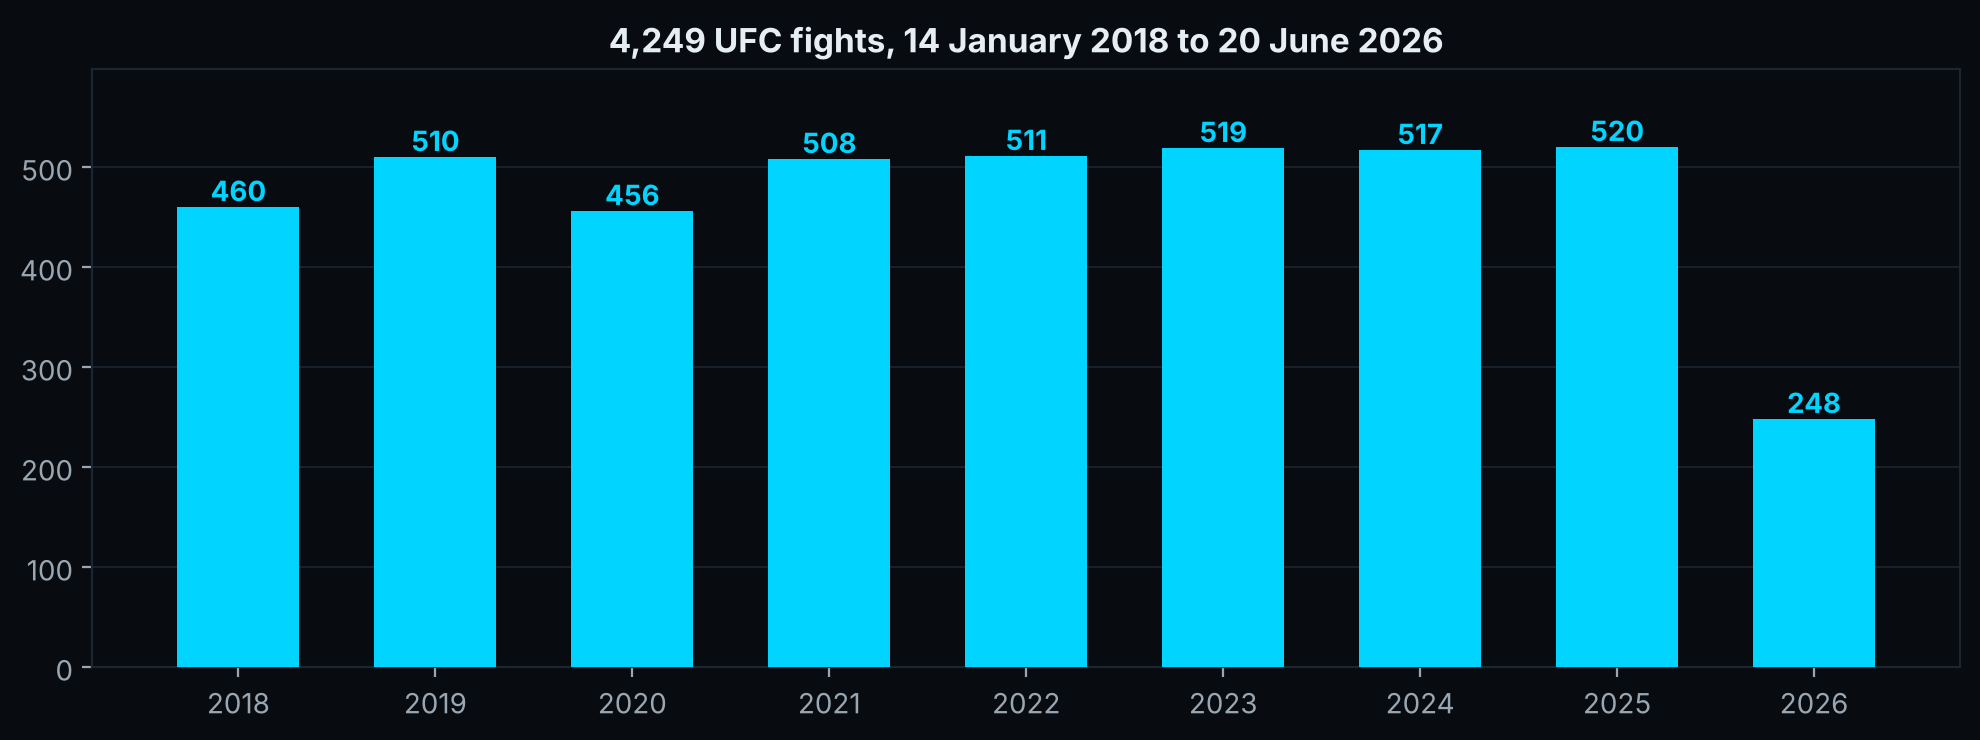

In [4]:
per_year = F["Date"].str[:4].value_counts().sort_index().to_dict()
check("fights per year, as listed", per_year == CLAIMS["fights_per_year"], " · ".join(f"{k} {v}" for k, v in per_year.items()))
check(f"from {CLAIMS['first_date']} to {CLAIMS['last_date']}, {CLAIMS['events']} events",
      F["Date"].min() == CLAIMS["first_date"] and F["Date"].max() == CLAIMS["last_date"] and F["Event"].nunique() == CLAIMS["events"])
key = F["Date"] + "|" + F[["Fighter_A", "Fighter_B"]].apply(lambda r: "|".join(sorted(r)), axis=1)
check("every fight is unique", not key.duplicated().any())
ids = pd.concat([F[["Fighter_A", "Fighter_A_ID"]].set_axis(["n", "i"], axis=1), F[["Fighter_B", "Fighter_B_ID"]].set_axis(["n", "i"], axis=1)])
two = ids.groupby("n")["i"].nunique()
check(f"{CLAIMS['fighters']:,} fighters, one name per ID; only the two Bruno Silva share a name",
      ids["i"].nunique() == CLAIMS["fighters"] and (ids.groupby("i")["n"].nunique() == 1).all() and two[two > 1].index.tolist() == ["Bruno Silva"]
      and (F["Fighter_A_ID"] != F["Fighter_B_ID"]).all())
res = {"Win": int(F["Winner"].notna().sum()), "Draw": int((F["Fighter_A_Result"] == "Draw").sum()),
       "No Contest": int((F["Fighter_A_Result"] == "No Contest").sum())}
check(f"{CLAIMS['results']['Win']:,} wins, {CLAIMS['results']['Draw']} draws, {CLAIMS['results']['No Contest']} no contests", res == CLAIMS["results"], str(res))
win_a, win_b = F["Fighter_A_Result"] == "Win", F["Fighter_B_Result"] == "Win"
check("Winner agrees with the results on every row; draws and no contests on both sides",
      (F.loc[win_a, "Winner"] == F.loc[win_a, "Fighter_A"]).all() and (F.loc[win_b, "Winner"] == F.loc[win_b, "Fighter_B"]).all()
      and ((F["Fighter_A_Result"] == "Loss") == win_b).all() and ((F["Fighter_B_Result"] == "Loss") == win_a).all()
      and (F.loc[~(win_a | win_b), "Fighter_A_Result"] == F.loc[~(win_a | win_b), "Fighter_B_Result"]).all())
check("methods, as listed", F["Method"].value_counts().to_dict() == CLAIMS["methods"], str(F["Method"].value_counts().to_dict()))
dec = F["Method"].str.contains("DEC")
check(f"decisions end at 5:00 of round 3 or 5, except {CLAIMS['technical_decisions']} technical decisions",
      F.loc[dec, "Round"].isin([3, 5]).all() and int((dec & (S["Finish_Time"] != "5:00")).sum()) == CLAIMS["technical_decisions"])
NEED = {False: {"U-DEC": {(3, 0, 0), (0, 3, 0)}, "S-DEC": {(2, 1, 0), (1, 2, 0)}, "M-DEC": {(2, 0, 1), (0, 2, 1)}},
        True: {"U-DEC": {(0, 0, 3)}, "M-DEC": {(1, 0, 2), (0, 1, 2)}, "S-DEC": {(1, 1, 1)}}}
fits, n_scores, loser_first = True, 0, 0
for i in F.index[dec]:
    txt = S.at[i, "Method_Detail"]
    if txt == "":
        continue
    m = re.fullmatch(r"(\d+)-(\d+), (\d+)-(\d+), (\d+)-(\d+)", txt)
    if not m:
        fits = False; continue
    v = list(map(int, m.groups())); pairs = list(zip(v[::2], v[1::2])); R = int(F.at[i, "Round"])
    pat = (sum(a > b for a, b in pairs), sum(a < b for a, b in pairs), sum(a == b for a, b in pairs))
    draw = S.at[i, "Fighter_A_Result"] == "Draw"
    fits &= all(7 * R <= x <= 10 * R for x in v) and pat in NEED[draw][S.at[i, "Method"]]
    n_scores += 1; loser_first += (not draw) and pat[1] > pat[0]
DS = CLAIMS["decision_scores"]
check(f"judges' scores on {DS['with_scores']:,} of the {DS['decisions']:,} decisions, each card fits the official method "
      f"(unanimous, split, majority, draw); {DS['loser_first']} written with the loser's score first",
      fits and n_scores == DS["with_scores"] and int(dec.sum()) == DS["decisions"] and loser_first == DS["loser_first"],
      f"{n_scores} with scores, {loser_first} loser first")
t = S["Finish_Time"].str.extract(r"^(\d):(\d\d)$").astype(float)
check("every finish time is m:ss, within 5:00, rounds 1 to 5", t.notna().all().all() and ((t[0] * 60 + t[1]) <= 300).all()
      and F["Round"].between(1, 5).all())
stats = [c for c in F.columns if c.endswith(("Knockdowns", "Sig_Strikes", "Takedowns", "Sub_Attempts"))]
check("fight stats of both fighters on every fight, whole numbers, never negative",
      len(stats) == 8 and F[stats].notna().all().all() and (F[stats] >= 0).all().all() and (F[stats] % 1 == 0).all().all())
check(f"{CLAIMS['women']} women's fights; {CLAIMS['titles']}",
      int((F["Gender"] == "Women").sum()) == CLAIMS["women"] and F["Title"].value_counts().to_dict() == CLAIMS["titles"]
      and (F.loc[F["Weight_Class"].str.startswith("Women"), "Gender"] == "Women").all()
      and int(((F["Gender"] == "Women") & ~F["Weight_Class"].str.startswith("Women")).sum()) == CLAIMS["women_catchweight"])
g_ = pd.concat([F[["Fighter_A_ID", "Gender"]].set_axis(["i", "g"], axis=1), F[["Fighter_B_ID", "Gender"]].set_axis(["i", "g"], axis=1)])
check(f"one gender per fighter on all his or her fights; {CLAIMS['women_catchweight']} women's fights at catchweight",
      (g_.groupby("i")["g"].nunique() == 1).all())

fig, ax = plt.subplots(figsize=(10, 3.8))
x = list(per_year)
ax.bar(x, per_year.values(), color=CYAN, width=0.62, zorder=3)
for i, v in enumerate(per_year.values()):
    ax.text(i, v + 6, f"{v}", ha="center", color=CYAN, fontsize=10, fontweight="bold")
ax.set_title(f"{len(F):,} UFC fights, 14 January 2018 to 20 June 2026")
ax.set_ylim(0, max(per_year.values()) * 1.15); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 4 · Prices

Every market is complete or empty for a source; every American price has its decimal twin; the margins and the lines
hold together.

In [5]:
def conv(us):
    return np.where(us > 0, 1 + us / 100, 1 + 100 / np.abs(us))

partial = {}
for s in SOURCES:
    for m, fl in MARKETS.items():
        pres = F[[f"{s}_{f}" for f in fl]].notna()
        n = int((pres.any(axis=1) & ~pres.all(axis=1)).sum())
        if n:
            partial[f"{s} {m}"] = n
check("every market is complete (both sides, with the line) or empty, for every source", not partial, str(partial))
bad = 0
for c in US_COLS:
    us, de = F[c], F[c[:-3] + "_Dec"]
    ok = us.notna()
    bad += int((np.abs(conv(us[ok]) - de[ok]) > 0.005 + 1e-9).sum())
check("every decimal price is the American price converted, rounded to 2 decimals", bad == 0, f"{bad} off")
check("no American price between -100 and +100", ((F[US_COLS].abs() >= 100) | F[US_COLS].isna()).all().all())
check("no placeholder price (10000 and beyond) on the moneyline and the total", not (F[CORE_US].abs() >= 10000).any().any())
over_bad = {}
for s in SOURCES:
    for m, (x, y) in PAIRS.items():
        a_, b_ = F[f"{s}_{x}"], F[f"{s}_{y}"]
        ov = imp(a_) + imp(b_)
        lo, hi = (1.015, 1.25) if m == "ML" else (1.0, 1.15)
        badm = a_.notna() & ((ov < lo) | (ov > hi) | ((m == "ML") & (a_ > 0) & (b_ > 0)))
        if badm.sum():
            over_bad[f"{s} {m}"] = int(badm.sum())
check("margins: moneyline 1.5% to 25%, never both sides plus money; total rounds 0% to 15%", not over_bad, str(over_bad))
lines = sorted(set(pd.concat([F[f"{s}_Total_Line"] for s in SOURCES]).dropna()))
check("every total line is 0.5, 1.5, 2.5, 3.5 or 4.5 rounds", lines == CLAIMS["total_lines"], str(lines))
T = pd.DataFrame({b: F[f"{b}_Total_Line"] for b in BOOKS})
n_diff = int((T.nunique(axis=1) > 1).sum())
check(f"the books did not all post the same total line on {CLAIMS['fights_books_on_different_total_lines']:,} fights",
      n_diff == CLAIMS["fights_books_on_different_total_lines"], f"{n_diff:,}")
P = pd.DataFrame({b: no_vig_a(F[f"{b}_ML_A_US"], F[f"{b}_ML_B_US"]) for b in BOOKS})
far = 0
for b in BOOKS:
    o_ = [x for x in BOOKS if x != b]
    enough = P[o_].notna().sum(axis=1) >= 2
    far += int((enough & ((P[b] - P[o_].median(axis=1)).abs() > 0.15)).sum())
check("no closing moneyline more than 15 points of probability from the other books' median, margin removed", far == 0, f"{far}")
own = int(sum(((T[b] - T[[x for x in BOOKS if x != b]].median(axis=1)).abs() >= 2).sum() for b in BOOKS))
check("each book keeps its own total line, even far from the others' (no rule on the height of the line)", own > 0, f"{own} book lines 2 rounds or more from the others' median")
yr = F["Date"].str[:4]
low = []
for b in SOURCES:
    med = P[[x for x in BOOKS if x != b]].median(axis=1)
    pb = pd.Series(no_vig_a(F[f"{b}_ML_A_US"], F[f"{b}_ML_B_US"]))
    for y in sorted(yr.unique()):
        m = (yr == y) & pb.notna() & med.notna()
        if m.sum() > 30 and np.corrcoef(pb[m], med[m])[0, 1] < 0.9:
            low.append(f"{b} {y}")
check("no book runs against the other books over a year (correlation of the probabilities above 0.9)", not low, str(low))

PASS  every market is complete (both sides, with the line) or empty, for every source   [{}]


PASS  every decimal price is the American price converted, rounded to 2 decimals   [0 off]
PASS  no American price between -100 and +100
PASS  no placeholder price (10000 and beyond) on the moneyline and the total
PASS  margins: moneyline 1.5% to 25%, never both sides plus money; total rounds 0% to 15%   [{}]
PASS  every total line is 0.5, 1.5, 2.5, 3.5 or 4.5 rounds   [[0.5, 1.5, 2.5, 3.5, 4.5]]
PASS  the books did not all post the same total line on 1,380 fights   [1,380]
PASS  no closing moneyline more than 15 points of probability from the other books' median, margin removed   [0]
PASS  each book keeps its own total line, even far from the others' (no rule on the height of the line)   [48 book lines 2 rounds or more from the others' median]


PASS  no book runs against the other books over a year (correlation of the probabilities above 0.9)   [[]]


## 5 · Coverage

Fights with a price, source by source and market by market, then year by year.

PASS  fights with a price, every source and market, as in the README   [Opener 4,209 · Betcris 3,662 · Heritage 4,184 · BetOnline 4,218 · Bovada 4,202 · BetAnything 2,472 · WilliamHill 4,224 · Everygame 4,201]
PASS  moneyline coverage year by year, as in the README
PASS  total rounds coverage year by year, as in the README
PASS  Betcris has no price from 2021-07-24 to 2022-08-20, a price on the fights just before and after, no total after 2026-03-21
PASS  BetAnything starts in September 2021   [2021-09-18]
PASS  Justin Ledet's 4 fights have no moneyline, but their total rounds


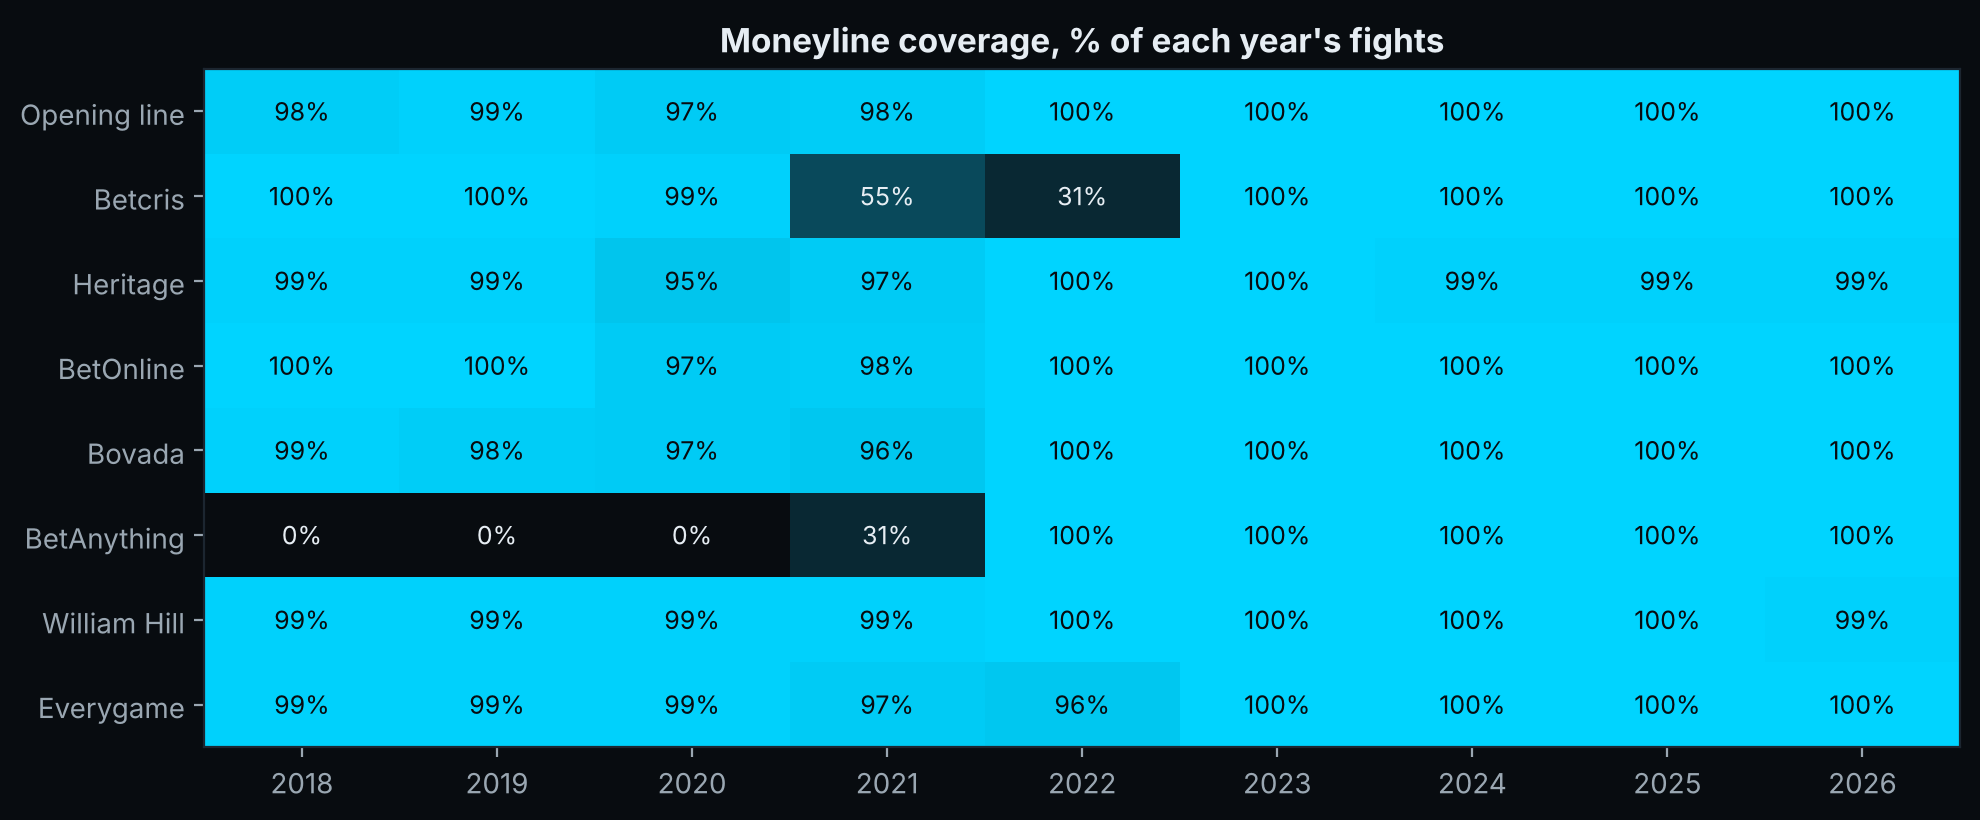

In [6]:
cov = {s: {m: int(F[f"{s}_{c}"].notna().sum()) for m, c in KEY.items()} for s in SOURCES}
check("fights with a price, every source and market, as in the README", cov == CLAIMS["coverage_fights"],
      " · ".join(f"{s} {cov[s]['ML']:,}" for s in SOURCES))
ml_year = {s: {y: int(round(100 * g[f"{s}_ML_A_US"].notna().mean())) for y, g in F.groupby(yr)} for s in SOURCES}
tot_year = {s: {y: int(round(100 * g[f"{s}_Total_Line"].notna().mean())) for y, g in F.groupby(yr)} for s in SOURCES}
check("moneyline coverage year by year, as in the README", ml_year == CLAIMS["ml_coverage_by_year_pct"])
check("total rounds coverage year by year, as in the README", tot_year == CLAIMS["total_coverage_by_year_pct"])
bg = CLAIMS["betcris_gap"]
in_gap = F["Date"].between(bg["from"], bg["to"])
check(f"Betcris has no price from {bg['from']} to {bg['to']}, a price on the fights just before and after, no total after {CLAIMS['betcris_last_total']}",
      F.loc[in_gap, [c for c in F.columns if c.startswith("Betcris_")]].isna().all().all()
      and F.loc[F["Date"] < bg["from"], "Betcris_ML_A_US"].notna().iloc[-20:].any()
      and F.loc[F["Date"] > bg["to"], "Betcris_ML_A_US"].notna().iloc[:20].any()
      and F.loc[F["Betcris_Total_Line"].notna(), "Date"].max() == CLAIMS["betcris_last_total"])
first_ba = F.loc[F["BetAnything_ML_A_US"].notna() | F["BetAnything_Total_Line"].notna(), "Date"].min()
check("BetAnything starts in September 2021", first_ba[:7] == CLAIMS["betanything_first_month"], first_ba)
n_ml = F[[f"{b}_ML_A_US" for b in BOOKS]].notna().sum(axis=1)
ledet = F[(F["Fighter_A"] == "Justin Ledet") | (F["Fighter_B"] == "Justin Ledet")]
check(f"Justin Ledet's {CLAIMS['ledet_fights_without_ml']} fights have no moneyline, but their total rounds",
      len(ledet) == CLAIMS["ledet_fights_without_ml"] and ledet[[f"{s}_ML_A_US" for s in SOURCES]].isna().all().all()
      and ledet["Heritage_Total_Line"].notna().all())

cmap = LinearSegmentedColormap.from_list("osd", [BG, "#0b3a4a", CYAN])
M = pd.DataFrame(ml_year).T
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks(range(M.shape[0]), [NAME.get(s, s) for s in M.index])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.iat[i, j]
        ax.text(j, i, f"{v}%", ha="center", va="center", fontsize=9, color=BG if v > 60 else FG)
ax.grid(False); ax.set_title("Moneyline coverage, % of each year's fights")
plt.tight_layout(); plt.show()

## 6 · Public betting split

The share of bets on each side, as published with the odds. The two sides add up to 100; a split recorded 0% / 0%
was left empty.

In [7]:
got = {"ML": int(F["ML_A_Bet%"].notna().sum()), "Total": int(F["Total_Over_Bet%"].notna().sum())}
check(f"betting split on {CLAIMS['betting_split_fights']['ML']:,} fights for the moneyline, "
      f"{CLAIMS['betting_split_fights']['Total']:,} for the total rounds", got == CLAIMS["betting_split_fights"], str(got))
ok = True
for x, y in (("ML_A_Bet%", "ML_B_Bet%"), ("Total_Over_Bet%", "Total_Under_Bet%")):
    ok &= bool((F[x].notna() == F[y].notna()).all()) and bool(((F[x] + F[y] - 100).abs().dropna() <= 1).all())
check("both sides given or both empty, and the two sides add up to 100", ok)

PASS  betting split on 4,234 fights for the moneyline, 4,177 for the total rounds   [{'ML': 4234, 'Total': 4177}]
PASS  both sides given or both empty, and the two sides add up to 100


## 7 · Props

From 9 May 2020: total rounds, will the fight go the distance, how will the fight end and method of victory, each with
the opening, consensus and best price of the comparison page, the number of sportsbooks quoting the market and their names.

In [8]:
pf = {m: int(F[f"{m}_NBooks"].notna().sum()) for m in PROPS}
check("fights with each prop market, as in the README", pf == CLAIMS["props_fights"], str(pf))
first = min(F.loc[F[f"{m}_NBooks"].notna(), "Date"].min() for m in PROPS)
check(f"no prop price before {CLAIMS['props_first_date']}", first == CLAIMS["props_first_date"]
      and F.loc[F["Date"] < CLAIMS["props_first_date"], [c for c in F.columns if c.split("_")[0] in PROPS]].isna().all().all())
agree = all((F[f"{m}_NBooks"].dropna().astype(int) == F.loc[F[f"{m}_NBooks"].notna(), f"{m}_Books"].fillna("")
             .map(lambda v: len([x for x in str(v).split(",") if x.strip()]))).all() for m in PROPS)
check("NBooks is the number of sportsbooks named in Books, for every market", agree)
names = sorted({x.strip() for m in PROPS for v in F[f"{m}_Books"].dropna() for x in str(v).split(",") if x.strip()})
check(f"{len(CLAIMS['prop_books'])} sportsbooks in the props", names == CLAIMS["prop_books"], ", ".join(names))
pm = True
for m, (x, y) in (("TR", ("Over", "Under")), ("Dist", ("Yes", "No"))):
    for k in ("Open", "Cons"):
        a_, b_ = F[f"{m}_{k}_{x}_US"], F[f"{m}_{k}_{y}_US"]
        ov = imp(a_) + imp(b_)
        pm &= bool((~(a_.notna() & ((ov < 1.0) | (ov > 1.25)))).all()) and bool((a_.notna() == b_.notna()).all())
check("total rounds and distance, opening and consensus: both sides, margin between 0% and 25%", pm)
bl = F["TR_Best_Over_Line"].notna() & (F["TR_Best_Over_Line"] != F["TR_Best_Under_Line"])
check(f"total rounds, best price: the best over and the best under on different lines on {CLAIMS['tr_best_lines_differ']} fights, "
      "each with its own line", int(bl.sum()) == CLAIMS["tr_best_lines_differ"]
      and (F["TR_Best_Over_Line"].notna() == F["TR_Best_Over_US"].notna()).all()
      and (F["TR_Best_Under_Line"].notna() == F["TR_Best_Under_US"].notna()).all(), f"{int(bl.sum())}")

PASS  fights with each prop market, as in the README   [{'TR': 2999, 'Dist': 2959, 'End': 2640, 'MOV': 2958}]
PASS  no prop price before 2020-05-09
PASS  NBooks is the number of sportsbooks named in Books, for every market
PASS  14 sportsbooks in the props   [BetMGM, BetRivers, Caesars, DraftKings, FanDuel, Fanatics, Fliff, Hard Rock, Kalshi, Novig, PartyCasino, ProphetX, SugarHouse, theScore Bet]
PASS  total rounds and distance, opening and consensus: both sides, margin between 0% and 25%
PASS  total rounds, best price: the best over and the best under on different lines on 528 fights, each with its own line   [528]


## 8 · Are these real market prices?

A real closing line is calibrated: when the market makes a fighter a 70% favourite, that fighter should win about 70%
of the time. The median of the seven books' closing moneylines, margin removed, against what happened (wins only).

PASS  fighter B, listed second, is the favourite on 70.8% of the fights   [70.8%]
PASS  the favourite won 2,755 of 4,094 decided fights   [2,755 / 4,094]


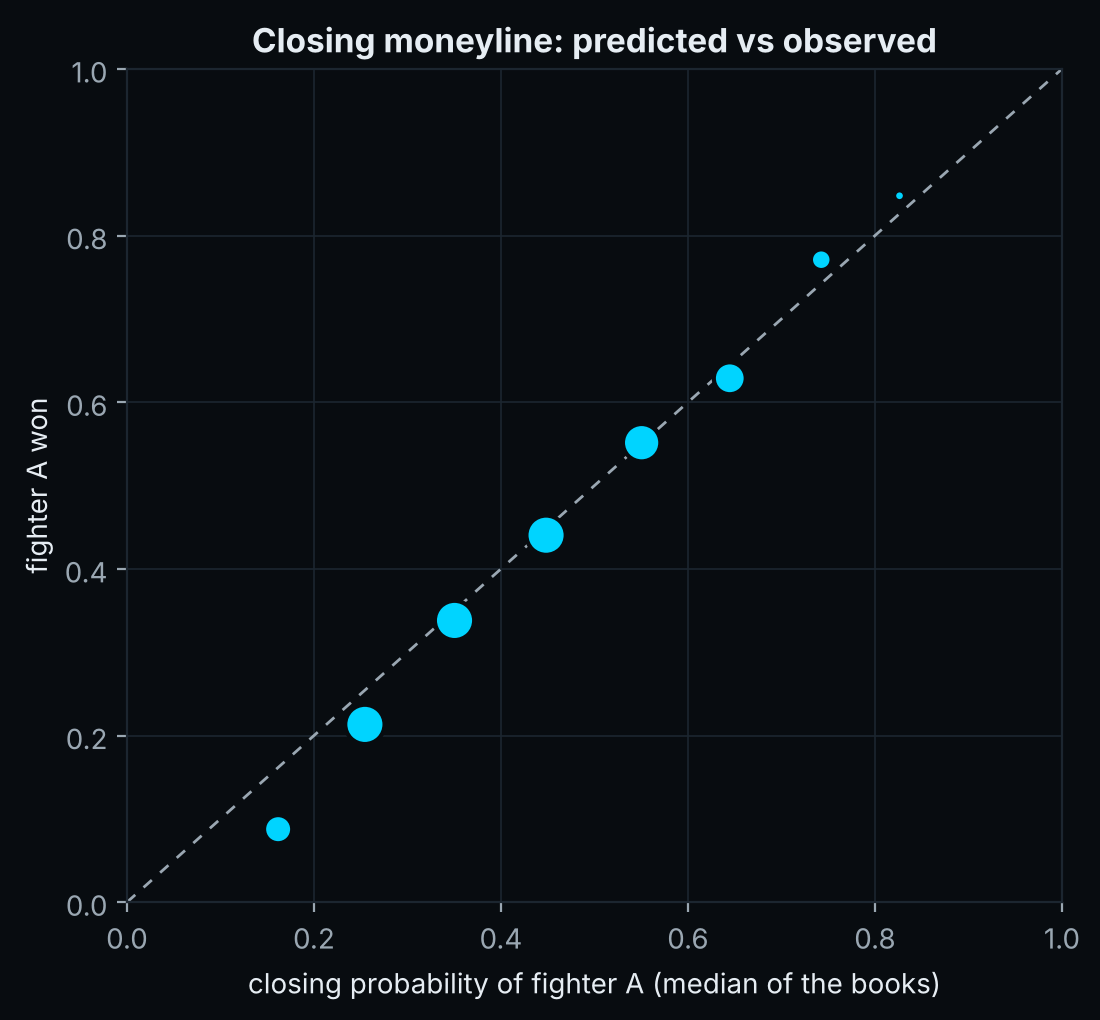

,p,freq,n
bin,,,
"(0.1, 0.2]",0.162,0.088,308
"(0.2, 0.3]",0.254,0.213,731
"(0.3, 0.4]",0.350,0.338,1103
"(0.4, 0.5]",0.448,0.440,865
"(0.5, 0.6]",0.550,0.551,544
"(0.6, 0.7]",0.645,0.629,396
"(0.7, 0.8]",0.743,0.771,166
"(0.8, 0.9]",0.826,0.848,46


In [9]:
p = P.median(axis=1)
decided = F["Fighter_A_Result"].isin(["Win", "Loss"]) & p.notna()
won_a = (F["Fighter_A_Result"] == "Win")
fav_b = p < 0.5
check(f"fighter B, listed second, is the favourite on {CLAIMS['b_favourite_pct']}% of the fights",
      round(100 * fav_b[p.notna()].mean(), 1) == CLAIMS["b_favourite_pct"], f"{100 * fav_b[p.notna()].mean():.1f}%")
fw = ((p > 0.5) & won_a) | ((p < 0.5) & (F["Fighter_B_Result"] == "Win"))
dd = decided & (p != 0.5)
check(f"the favourite won {CLAIMS['favourite_won'][0]:,} of {CLAIMS['favourite_won'][1]:,} decided fights",
      [int(fw[dd].sum()), int(dd.sum())] == CLAIMS["favourite_won"], f"{int(fw[dd].sum()):,} / {int(dd.sum()):,}")
cal = pd.DataFrame({"p": p[decided], "hit": won_a[decided]})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.1))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 30]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 3, 12, 200), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("closing probability of fighter A (median of the books)"); ax.set_ylabel("fighter A won")
ax.set_title("Closing moneyline: predicted vs observed")
plt.tight_layout(); plt.show()
cb.round(3)

## 9 · The fights on the listing's images

The images of the listing are drawn from the file. Every number they show, recomputed.

In [10]:
def fight(d, name):
    g = F[(F["Date"] == d) & ((F["Fighter_A"] == name) | (F["Fighter_B"] == name))]
    assert len(g) == 1, (d, name)
    return g.iloc[0]

S5 = ["Opener", "Betcris", "BetOnline", "Bovada", "Heritage"]
img1 = {}
for k in COVERS["cover_1_winner_ml"]:
    d, w = k.split("|"); r = fight(d, w); side = "A" if r["Fighter_A"] == w else "B"
    img1[k] = [int(r[f"{s}_ML_{side}_US"]) for s in S5] if r["Winner"] == w else None
check("image 1: moneyline of the winner of five title fights, opening line, Betcris, BetOnline, Bovada, Heritage",
      img1 == COVERS["cover_1_winner_ml"])
c2 = COVERS["cover_2_fight"]; r = fight(c2["date"], c2["a"])
img2 = {s: [int(r[f"{s}_ML_A_US"]), int(r[f"{s}_ML_B_US"]), float(r[f"{s}_Total_Line"]), int(r[f"{s}_Total_Over_US"]),
            int(r[f"{s}_Total_Under_US"])] for s in SOURCES}
pr2 = {"dist_yes": int(r["Dist_Cons_Yes_US"]), "dist_no": int(r["Dist_Cons_No_US"]), "mov_a_ko": int(r["MOV_Cons_A_KOTKO_US"]),
       "bet_ml_a": int(r["ML_A_Bet%"]), "bet_over": int(r["Total_Over_Bet%"])}
check("image 2: UFC 298, every source's moneylines and total rounds, props and betting split",
      img2 == c2["rows"] and pr2 == c2["props"] and [r["Fighter_B"], r["Winner"], r["Method"], str(int(r["Round"]))]
      == [c2["b"], c2["winner"], c2["method"], c2["round"]])
img3 = {}
for _, g in F[F["Event"] == COVERS["cover_3_moves"]["event"]].iterrows():
    k = f"{g['Fighter_A']}|{g['Fighter_B']}"
    if k in COVERS["cover_3_moves"]["rows"]:
        img3[k] = [int(g[f"{s}_ML_A_US"]) for s in ("Opener", "Betcris", "Bovada", "Heritage")] + [g["Winner"]]
check("image 3: UFC 300, first fighter's moneyline at the opening line and at Betcris, Bovada, Heritage, and the winner",
      img3 == COVERS["cover_3_moves"]["rows"])
img4 = {}
for _, g in F[F["Event"] == COVERS["cover_4_public_split"]["event"]].iterrows():
    k = f"{g['Fighter_A']}|{g['Fighter_B']}"
    if k in COVERS["cover_4_public_split"]["rows"]:
        img4[k] = [int(g["ML_A_Bet%"]), int(g["ML_B_Bet%"]), int(g["Total_Over_Bet%"]), g["Winner"], g["Method"], str(int(g["Round"]))]
check("image 4: UFC 317, betting split and result of the top five fights", img4 == COVERS["cover_4_public_split"]["rows"])
img5 = {s: [round(100 * F[f"{s}_{c}"].notna().mean(), 1) for c in KEY.values()] for s in SOURCES}
check("image 5: share of fights with a price, every source and market, and the prop counts",
      img5 == COVERS["cover_5_coverage_pct"] and {m: int(F[f"{m}_NBooks"].notna().sum()) for m in PROPS} == COVERS["cover_5_props"])
t6 = COVERS["cover_6_tiles"]
check(f"image 6: {t6['fights']:,} fights, {t6['events']} events, {t6['fighters']:,} fighters, {t6['sources']} sources, "
      f"{t6['prices']:,} prices, {t6['columns']} columns",
      [len(F), F["Event"].nunique(), ids["i"].nunique(), len(SOURCES), int(F[US_COLS].notna().sum().sum()), F.shape[1]]
      == [t6["fights"], t6["events"], t6["fighters"], t6["sources"], t6["prices"], t6["columns"]])

PASS  image 1: moneyline of the winner of five title fights, opening line, Betcris, BetOnline, Bovada, Heritage
PASS  image 2: UFC 298, every source's moneylines and total rounds, props and betting split


PASS  image 3: UFC 300, first fighter's moneyline at the opening line and at Betcris, Bovada, Heritage, and the winner
PASS  image 4: UFC 317, betting split and result of the top five fights
PASS  image 5: share of fights with a price, every source and market, and the prop counts
PASS  image 6: 4,249 fights, 354 events, 1,450 fighters, 8 sources, 253,510 prices, 228 columns


## 10 · Said plainly, checked

The limits the listing states up front, recomputed.

In [11]:
check("odds stop on 20 June 2026", F["Date"].max() == "2026-06-20")
check("one opening line (Opener), no opening price per book: the seven books carry closing prices only",
      not any(c.startswith(tuple(f"{b}_Open" for b in BOOKS)) for c in F.columns))
check("no BetAnything price before September 2021",
      F.loc[F["Date"] < "2021-09-01", [c for c in F.columns if c.startswith("BetAnything_")]].isna().all().all())
check(f"results as they stand: overturned results are no contests ({CLAIMS['overturned'].get('No Contest', 0)}) or draws "
      f"({CLAIMS['overturned'].get('Draw', 0)}), with no winner",
      F.loc[F["Method"] == "Overturned", "Fighter_A_Result"].value_counts().to_dict() == CLAIMS["overturned"]
      and F.loc[F["Method"].isin(["Overturned", "CNC"]), "Winner"].isna().all())

PASS  odds stop on 20 June 2026
PASS  one opening line (Opener), no opening price per book: the seven books carry closing prices only
PASS  no BetAnything price before September 2021
PASS  results as they stand: overturned results are no contests (23) or draws (1), with no winner


## 11 · Summary

In [12]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

54 / 54 claims verified


Result,Claim,Detail
PASS,"4,249 fights, one row each, Fight_ID 1 to 4,249 in date order","4,249 rows"
PASS,"228 columns: 36 for the fight, 9 per source for 8 sources, 120 for the props",228 columns
PASS,"UTF-8 with BOM, semicolon-separated, Windows line ends",
PASS,no BookMaker or Ozoon column (removed in this edition),
PASS,"253,510 prices (117,358 core, 136,152 props), each in American and decimal odds","117,358 + 136,152"
PASS,"fights per year, as listed",2018 460 · 2019 510 · 2020 456 · 2021 508 · 2022 511 · 2023 519 · 2024 517 · 2025 520 · 2026 248
PASS,"from 2018-01-14 to 2026-06-20, 354 events",
PASS,every fight is unique,
PASS,"1,450 fighters, one name per ID; only the two Bruno Silva share a name",
PASS,"4,173 wins, 33 draws, 43 no contests","{'Win': 4173, 'Draw': 33, 'No Contest': 43}"


---

Everything above ran on the file a buyer downloads. The README in the ZIP holds the full column dictionary, the coverage
of every source year by year, how each price was checked, what changed since the previous edition and every known
limitation.

👉 🥊 **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/iiyon?utm_source=github&utm_medium=notebook&utm_campaign=ufc_oc&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/ufc-opening-closing-odds-7-books-props-fight-stats-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=ufc_oc&utm_content=whop_bottom) 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*